# Notebook 03: Filtering, spectra and signal-to-noise

**Goal (about 2.5 hours, can be split over two sessions):** find out where the frequencies in a seismogram come from (the earthquake, the rock between it and the station, and the instrument), then work through the processing that comes before every splitting measurement, and see what each step does to the delays of a few hundredths of a second that splitting measures.

By the end you should be able to explain, for STAR:

- why its S waves look strongest between about 3 and 20 Hz, and what the station cannot record at all;
- what the pipeline's filter bank, SNR gate and dominant period each measure, and why each one is a choice;
- why a delay of 0.05 s is hard to see, and at which frequencies.

Read along with ObsPy's [Filtering Seismograms](https://docs.obspy.org/tutorial/code_snippets/filtering_seismograms.html) page and Seismo-Live's [07 Basic Processing Exercise](https://seismo-live.github.io/html/ObsPy/07_Basic_Processing_Exercise_wrapper.html). Words in **bold** are defined where they first appear; section 9 collects them in a glossary.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys, warnings
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats
print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


In [2]:
import obspy
from rainier_sws import timing
cat = data.load_station_catalog("STAR")
row = cat[cat.evid == 61504668].iloc[0]
ev = data.get_event_stream("STAR", row, allow_download=False)
origin, p_time, s_time, p_off, s_off = measure.pick_offsets(ev, row)
fs = ev[0].stats.sampling_rate
R = timing.hypocentral_distance_km(row, data.load_stations().set_index("station"))
print("sampling rate", fs, "Hz; P at", round(p_off, 2), "s, S at", round(s_off, 2), "s after trace start")
print(f"magnitude {row.event_magnitude}, {R:.1f} km from STAR; S arrives {s_time - origin:.2f} s after the origin, "
      f"{s_time - p_time:.2f} s after P")

sampling rate 100.0 Hz; P at 5.88 s, S at 6.47 s after trace start
magnitude 0.4, 4.6 km from STAR; S arrives 1.47 s after the origin, 0.59 s after P


This is the earthquake in figure 3 of the preliminary results, the one notebook 05 reproduces: magnitude 0.4, 4.6 km from STAR. Its S wave arrives only 0.59 s after its P wave, which will matter more than once below. `ev` holds its three components, rotated to true Z, N and E (notebook 02).

## 1. Where the frequencies come from

A seismogram is the last link of a chain, and each link changes how much of each frequency gets through. Treat each link as a linear filter (the ECE picture): in the time domain the links are convolved, in the frequency domain they multiply,

$$\text{recorded}(f) = \text{source}(f) \times \text{path}(f) \times \text{instrument}(f) + \text{noise}(f).$$

Each factor has a shape you can predict.

- **Source.** An earthquake is sudden slip on a patch of fault. Its size is the **seismic moment**, $M_0$ = rigidity × slip area × average slip (in N m), usually quoted as a **moment magnitude**, $M_w = (\log_{10} M_0 - 9.1) / 1.5$ (Hanks and Kanamori, 1979). The simplest useful model of the waves it sends out (Brune, 1970) has one **corner frequency**, $f_c$: the spectrum of the ground *displacement* is flat below $f_c$ and falls as $1/f^2$ above it. A smaller earthquake slips on a smaller patch for a shorter time, so its corner is higher: $f_c \approx 0.49\,\beta\,(\Delta\sigma / M_0)^{1/3}$, with $\beta$ the S-wave speed at the source and $\Delta\sigma$ the **stress drop**, how much the shear stress on the fault fell (typically 0.1 to 10 MPa). STAR records ground *velocity*, which is displacement × $2\pi f$, so in velocity the source spectrum rises in proportion to $f$ up to the corner and falls as $1/f$ after it.
- **Path.** Rock is not perfectly elastic. Every cycle of a wave loses a small fraction of its energy to friction on cracks and to fluid squeezed through pores: **attenuation**. It is measured by the **quality factor** $Q$: each cycle loses about $2\pi/Q$ of the wave's energy, so a low $Q$ means strong attenuation. After travelling for a time $T$ the amplitude has fallen by $\exp(-\pi f t^*)$, where $t^* = T/Q$. High frequencies make more cycles on the way, so they lose more. Hot, fractured, fluid-filled volcanic rock has a low $Q$. **Scattering** off small lumps and cracks also takes high frequencies out of the direct wave and puts them into the **coda**, the tail of scattered waves that follows every arrival.
- **Instrument.** STAR's sensor is a **geophone**, the mass on a spring of notebook 01, with a **natural frequency** of 2 Hz: well below it, the mass simply moves with the ground, the coil sees little relative motion, and the output falls as $f^2$. The voltage then travels by analog radio telemetry (STAR is still analog; see the README), through filters that cut off above about 20 to 30 Hz, to a receiving site where it is digitized. The combined effect is the **instrument response**: how many output counts one m/s of ground velocity produces, at each frequency. It is published with the data in a format called **StationXML**; `data.load_inventory` reads the repo's copy (`data/stationxml/`) or fetches it from EarthScope.
- **Noise.** Everything recorded that is not our earthquake: the ocean **microseism** (the whole crust shaken by ocean waves, at 0.05 to 0.5 Hz, far below STAR's band), wind on an exposed site, glaciers and rockfall, the telemetry's electronics and, during a swarm, the coda of the previous earthquake. Section 2 measures it.

The figure draws each factor on its own. The grey band, in every panel, is STAR's **passband**: the frequencies where its response is within a factor of $\sqrt 2$ (3 dB) of its peak, the range this station records well.

STAR's passband (response within 3 dB of its peak): 2.3 to 19.9 Hz; at 40 Hz the response is 54 times below its peak
attenuation halves the amplitude at 22 Hz (t* = 0.01 s), 11 Hz (t* = 0.02 s), 6 Hz (t* = 0.04 s)


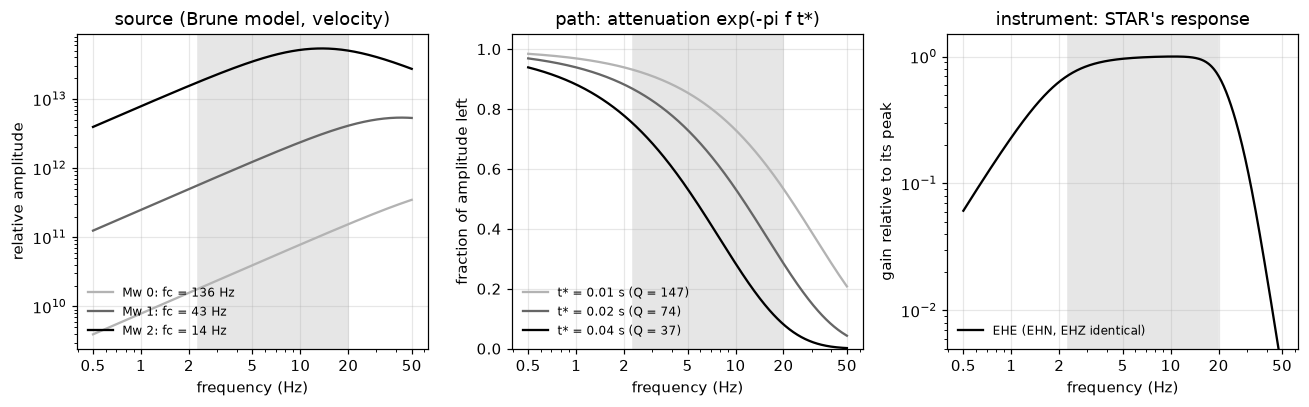

In [3]:
inv = data.load_inventory("STAR")
resp = inv.select(channel="EHE")[0][0][0].response
f = np.logspace(np.log10(0.5), np.log10(50), 400)
H = np.abs(resp.get_evalresp_response_for_frequencies(f, output="VEL"))
H /= H.max()
f_lo, f_hi = f[H >= 1 / np.sqrt(2)].min(), f[H >= 1 / np.sqrt(2)].max()

import matplotlib.ticker as mticker
def plain_ticks(ax, ticks):
    """Label a logarithmic x axis with plain numbers."""
    ax.set_xticks(ticks); ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%g")); ax.xaxis.set_minor_formatter(mticker.NullFormatter())

beta, stress_drop = 3000.0, 1e6          # S-wave speed at the source (m/s) and stress drop (Pa)
def brune_velocity(f, Mw):
    """Brune (1970) source spectrum in ground velocity (arbitrary units) and its corner frequency (Hz)."""
    M0 = 10 ** (1.5 * Mw + 9.1)                                   # seismic moment, N m
    fc = 0.49 * beta * (stress_drop / M0) ** (1 / 3)
    return M0 * 2 * np.pi * f / (1 + (f / fc) ** 2), fc

travel = s_time - origin                 # S travel time, s
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True)
for Mw, c in [(0, "0.7"), (1, "0.4"), (2, "k")]:
    v, fc = brune_velocity(f, Mw)
    axes[0].loglog(f, v, color=c, lw=1.5, label=f"Mw {Mw}: fc = {fc:.0f} Hz")
axes[0].set(title="source (Brune model, velocity)", ylabel="relative amplitude")
for tstar, c in [(0.01, "0.7"), (0.02, "0.4"), (0.04, "k")]:
    axes[1].semilogx(f, np.exp(-np.pi * f * tstar), color=c, lw=1.5, label=f"t* = {tstar} s (Q = {travel / tstar:.0f})")
axes[1].set(title="path: attenuation exp(-pi f t*)", ylabel="fraction of amplitude left", ylim=(0, 1.05))
axes[2].loglog(f, H, color="k", lw=1.5, label="EHE (EHN, EHZ identical)")
axes[2].set(title="instrument: STAR's response", ylabel="gain relative to its peak", ylim=(5e-3, 1.5))
for ax in axes:
    ax.axvspan(f_lo, f_hi, color="0.9", zorder=0)
    ax.set_xlabel("frequency (Hz)"); ax.legend(fontsize=8, frameon=False, loc="lower left")
    plain_ticks(ax, [0.5, 1, 2, 5, 10, 20, 50])
plt.tight_layout()
print(f"STAR's passband (response within 3 dB of its peak): {f_lo:.1f} to {f_hi:.1f} Hz; "
      f"at 40 Hz the response is {1 / H[np.argmin(np.abs(f - 40))]:.0f} times below its peak")
print("attenuation halves the amplitude at", ", ".join(f"{np.log(2) / (np.pi * t):.0f} Hz (t* = {t} s)" for t in (0.01, 0.02, 0.04)))

Read the three panels together, inside the grey band:

- **Source.** With a stress drop of 1 MPa the corner frequency of an Mw 0 earthquake is above 100 Hz, of Mw 1 about 40 Hz, of Mw 2 about 14 Hz. Most swarm earthquakes are around magnitude 0.5, so inside STAR's band their source spectrum is still *rising*: the same shape at every size, only the level changes. (PNSN's magnitudes for earthquakes this small are local or duration magnitudes, which match Mw only roughly, and the stress drop is not known; read these curves as shapes, not predictions.)
- **Path.** S takes about 1.5 s to reach STAR. For $Q$ between about 40 and 150 ($t^*$ from 0.04 to 0.01 s), attenuation halves the amplitude somewhere between 6 and 22 Hz.
- **Instrument.** Below 2 Hz the geophone loses sensitivity as $f^2$, and above about 20 Hz the telemetry filters cut steeply: at 40 Hz the response is about 50 times below its peak.

So at STAR the shape of an S spectrum is set mostly by the path and the instrument, not by the size of the earthquake: a rising source spectrum, multiplied by a falling attenuation curve, cut by the instrument at both ends. That is a prediction you can test. If it holds, the band the filter bank picks and the dominant period should hardly depend on magnitude; exercises 3 and 4 check.

### Counts, and why splitting does not remove the response

The waveforms are in **counts**, the digitizer's integer output. Dividing by the response at each frequency would turn them into ground velocity in m/s (ObsPy's `Trace.remove_response`). Splitting does not need that, for the reason notebook 01 gave: it compares the two horizontal components with *each other*, their timing and their amplitude ratio. Here is STAR's response on all three channels at a few frequencies:

In [4]:
f_check = np.array([1.0, 5.0, 10.0, 20.0])
print("frequency (Hz):           ", f_check)
for ch in inv[0][0]:
    r_ = ch.response.get_evalresp_response_for_frequencies(f_check, output="VEL")
    print(f"{ch.code} gain (counts per m/s):", [f"{a:.2e}" for a in np.abs(r_)])
    print(f"    phase (degrees):       ", np.angle(r_, deg=True).round(0))
print("sensor:", inv[0][0][0].sensor.description)

frequency (Hz):            [ 1.  5. 10. 20.]
EHE gain (counts per m/s): ['2.15e+09', '8.96e+09', '9.33e+09', '6.55e+09']
    phase (degrees):        [ 126.  -24. -110.   81.]
EHN gain (counts per m/s): ['2.15e+09', '8.96e+09', '9.33e+09', '6.55e+09']
    phase (degrees):        [ 126.  -24. -110.   81.]
EHZ gain (counts per m/s): ['2.15e+09', '8.96e+09', '9.33e+09', '6.55e+09']
    phase (degrees):        [ 126.  -24. -110.   81.]
sensor: L22D08-0621=McVCO=MC8=PSNgw-XXXX


The three are identical: the components share one model of sensor and one telemetry chain. The metadata's description of the sensor spells out that chain: an L-22D geophone, a McVCO (the voltage-controlled oscillator that turns the signal into a tone for the radio link) and the equipment that receives and digitizes it. Dividing two traces by the same thing changes neither their time difference nor their amplitude ratio. That includes the **phase response**, the second row: the response shifts different frequencies by different fractions of a cycle, which delays and reshapes every arrival a little, but in the same way on both horizontals.

Two caveats. "Identical" means identical *metadata*: two real geophones differ slightly, and exercise 5 asks whether that could fake a splitting delay. And STAR's absolute amplitudes are 15 to 18 times below what this response says (README), which would matter for a magnitude, not for splitting.

## 2. The spectrum of one earthquake

The **Fourier amplitude spectrum** of a window of a trace says how much of each frequency the window contains: the amplitudes of the sine waves that add up to it (`np.fft.rfft`). Three facts govern every spectrum in this lesson:

- The **frequency resolution** is 1 / (window length): a 0.4 s window gives one value every 2.5 Hz and cannot tell 3 Hz from 4 Hz. Short windows give blurry spectra.
- The highest frequency a sampled trace can hold is the **Nyquist frequency**, half the sampling rate: 50 Hz here.
- A window cut out of a trace starts and ends abruptly, and those jumps add frequencies that are not in the ground motion. So each window is first **detrended** (its mean and straight-line trend removed) and **tapered**: multiplied by a smooth bump that falls to zero at both ends (the Hann window).

S comes only 0.59 s after P, so the windows have to be short. We compare three windows of 0.4 s on the two horizontals (combined as the root-mean-square of the N and E spectra): **pre-event noise**, ending 0.1 s before P; the **P coda**, the 0.4 s just before S, after the P wave's first swing has passed; and **S**, starting 0.05 s before the S pick.

S spectrum peaks at 12.2 Hz; S / pre-event noise at the peak: 25x, S / P coda: 11x


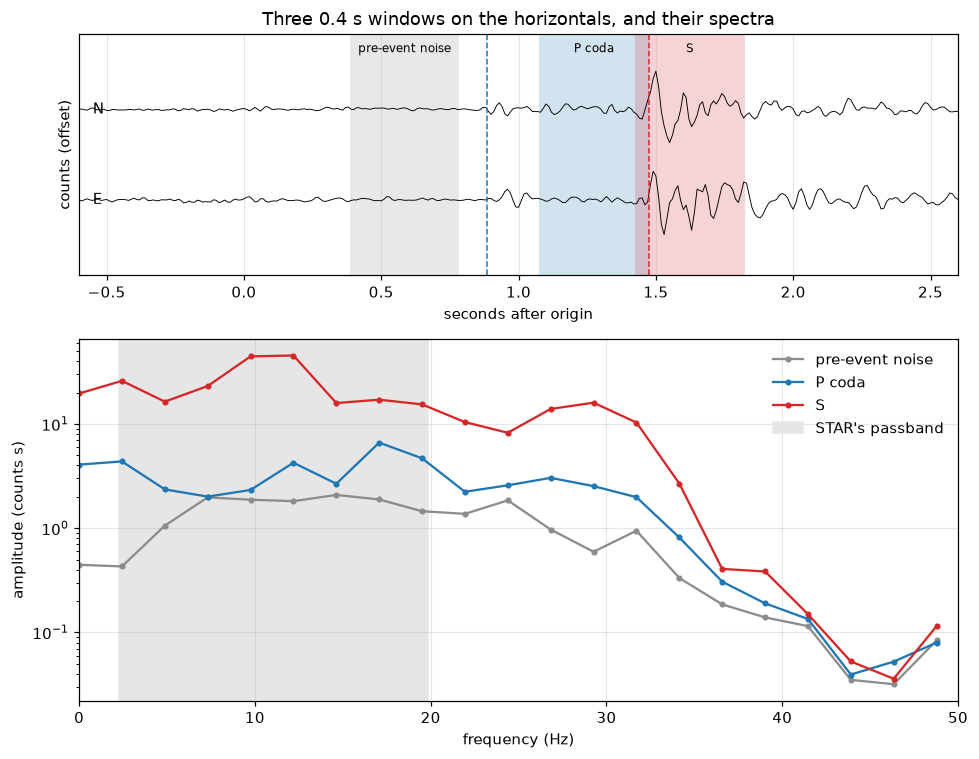

In [5]:
def window(tr, t_start, t_end):
    return tr.slice(tr.stats.starttime + t_start, tr.stats.starttime + t_end).data.astype(float)

def amplitude_spectrum(x, fs):
    """Fourier amplitude of one window, detrended and Hann-tapered first."""
    x = (x - np.polyval(np.polyfit(np.arange(len(x)), x, 1), np.arange(len(x)))) * np.hanning(len(x))
    return np.fft.rfftfreq(len(x), 1 / fs), np.abs(np.fft.rfft(x)) / fs

L = 0.4                                            # window length (s): one value every 1 / L = 2.5 Hz
starts = {"pre-event noise": p_off - 0.1 - L, "P coda": s_off - L, "S": s_off - 0.05}   # s after trace start
colors = {"pre-event noise": "0.55", "P coda": "tab:blue", "S": "tab:red"}
tr = ev.select(channel="??E")[0].copy().detrend("linear")
horizontals = [ev.select(channel=f"??{c}")[0] for c in "NE"]
spectra = {}
for name, t0 in starts.items():
    amps = [amplitude_spectrum(window(h, t0, t0 + L), fs) for h in horizontals]
    freqs = amps[0][0]
    spectra[name] = np.sqrt((amps[0][1] ** 2 + amps[1][1] ** 2) / 2)      # root-mean-square of N and E

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(9, 7), gridspec_kw={"height_ratios": [2, 3]})
t_start = ev[0].stats.starttime - origin           # trace start, seconds after origin
for h, off, label in [(horizontals[0], 1500, "N"), (horizontals[1], -1500, "E")]:
    d = h.data - h.data.mean()
    ax0.plot(h.times() + t_start, d + off, "k", lw=0.6); ax0.text(-0.55, off, label, va="center")
for name, t0 in starts.items():
    ax0.axvspan(t0 + t_start, t0 + t_start + L, color=colors[name], alpha=0.2, lw=0)
    ax0.text(t0 + t_start + L / 2, 3400, name, ha="center", fontsize=8)
ax0.axvline(p_time - origin, color="tab:blue", ls="--", lw=1); ax0.axvline(s_time - origin, color="tab:red", ls="--", lw=1)
ax0.set(xlim=(-0.6, 2.6), ylim=(-4000, 4000), xlabel="seconds after origin", ylabel="counts (offset)", yticks=[])
for name in starts:
    ax1.semilogy(freqs, spectra[name], color=colors[name], lw=1.5, marker="o", ms=3, label=name)
ax1.axvspan(f_lo, f_hi, color="0.9", zorder=0, label="STAR's passband")
ax1.set(xlabel="frequency (Hz)", ylabel="amplitude (counts s)", xlim=(0, 50))
ax1.legend(frameon=False)
ax0.set_title("Three 0.4 s windows on the horizontals, and their spectra")
plt.tight_layout()
peak = freqs[np.argmax(spectra["S"])]
print(f"S spectrum peaks at {peak:.1f} Hz; S / pre-event noise at the peak: {spectra['S'].max() / spectra['pre-event noise'][np.argmax(spectra['S'])]:.0f}x, "
      f"S / P coda: {spectra['S'].max() / spectra['P coda'][np.argmax(spectra['S'])]:.0f}x")

For this earthquake:

- **S** stands well above the pre-event noise, by a factor of 4 to 60, at every frequency up to about 32 Hz, and peaks at 10 to 12 Hz. Above about 33 Hz all three spectra sink together. That is the instrument's upper edge, not the end of the earthquake's spectrum.
- The **P coda** sits between the two: up to ten times above the pre-event noise at the lowest frequencies, close to it around 7 to 10 Hz, and 11 times below S at S's peak. Remember it: it is what the pipeline's SNR compares S with (section 5).
- The lowest point, below 2.5 Hz, says little: a 0.4 s window holds less than one cycle of anything that slow. That limit belongs to the window, not to the earthquake.

One event in one short window is noisy. The median over every cached STAR event is not, and it shows what shapes the spectrum. Each event's spectrum is scaled to 1 between 7 and 13 Hz before taking the median, so the figure compares shapes, not levels. The pre-event noise uses the 4.5 s before P, which resolves 0.22 Hz.

frequency (Hz):             [ 2.5  5.  10.  15.  20.  25.  30.  35.  40.  45. ]
S / response:               [0.96 0.84 1.09 0.82 0.82 0.7  0.87 0.59 0.27 0.21]
pre-event noise / response: [1.88 1.2  0.97 0.95 0.8  0.82 1.14 1.06 1.87 2.74]


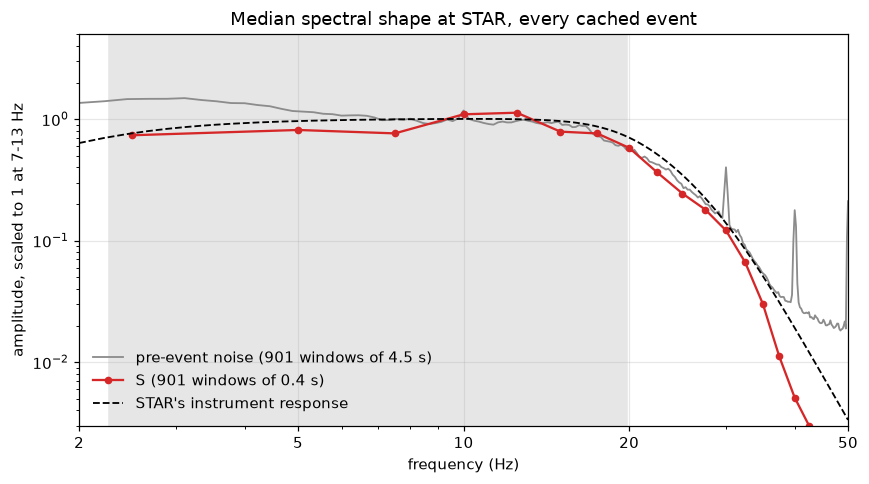

In [6]:
cached = data.describe_cache("STAR").query("complete").evid
n_noise = 450                                   # 4.5 s of pre-event noise: one value every 0.22 Hz
S_all, N_all = [], []
for _, r in cat[cat.evid.isin(cached)].iterrows():
    e = data.get_event_stream("STAR", r, allow_download=False)
    _, _, _, p_o, s_o = measure.pick_offsets(e, r)
    hs = [e.select(channel=f"??{c}")[0].data.astype(float) for c in "NE"]
    i, j = round((s_o - 0.05) * fs), round((p_o - 0.2) * fs)
    S_all.append(np.sqrt(np.mean([amplitude_spectrum(h[i:i + round(L * fs)], fs)[1] ** 2 for h in hs], axis=0)))
    if j >= n_noise:
        N_all.append(np.sqrt(np.mean([amplitude_spectrum(h[j - n_noise:j], fs)[1] ** 2 for h in hs], axis=0)))
f_S, f_N = np.fft.rfftfreq(round(L * fs), 1 / fs), np.fft.rfftfreq(n_noise, 1 / fs)

def median_shape(spectra, fr):
    """Median over events of each spectrum, scaled to 1 between 7 and 13 Hz."""
    a = np.array(spectra)
    return np.median(a / a[:, (fr >= 7) & (fr <= 13)].mean(axis=1, keepdims=True), axis=0)

H_ref = np.abs(resp.get_evalresp_response_for_frequencies(np.arange(7, 13.01, 0.25), output="VEL")).mean()
def response_shape(fr):
    """STAR's response, scaled to 1 between 7 and 13 Hz."""
    return np.abs(resp.get_evalresp_response_for_frequencies(np.asarray(fr, dtype=float), output="VEL")) / H_ref

S_med, N_med = median_shape(S_all, f_S), median_shape(N_all, f_N)
fig, ax = plt.subplots(figsize=(8, 4.5))
kS, kN = f_S >= 2, f_N >= 2
ax.loglog(f_N[kN], N_med[kN], color="0.55", lw=1.2, label=f"pre-event noise ({len(N_all)} windows of 4.5 s)")
ax.loglog(f_S[kS], S_med[kS], color="tab:red", lw=1.5, marker="o", ms=4, label=f"S ({len(S_all)} windows of 0.4 s)")
ax.loglog(f_N[kN], response_shape(f_N[kN]), "k--", lw=1.2, label="STAR's instrument response")
ax.axvspan(f_lo, f_hi, color="0.9", zorder=0)
ax.set(xlabel="frequency (Hz)", ylabel="amplitude, scaled to 1 at 7-13 Hz", xlim=(2, 50), ylim=(3e-3, 5),
       title="Median spectral shape at STAR, every cached event")
ax.legend(frameon=False, loc="lower left")
plain_ticks(ax, [2, 5, 10, 20, 50])
plt.tight_layout()
fq = np.array([2.5, 5, 10, 15, 20, 25, 30, 35, 40, 45])
print("frequency (Hz):            ", fq)
print("S / response:              ", np.round([S_med[np.argmin(np.abs(f_S - x))] for x in fq] / response_shape(fq), 2))
print("pre-event noise / response:", np.round([np.median(N_med[np.abs(f_N - x) < 1]) for x in fq] / response_shape(fq), 2))

Three curves, one shape. Above about 10 Hz the median S spectrum, the median pre-event noise and the instrument response fall together, to 12 to 16 percent of their 7-13 Hz level at 30 Hz. Divide the S curve by the response (the first printed row) and what is left, the shape of the ground motion itself, is nearly flat: within 30 percent of 1 from 2.5 to 30 Hz. So in this band the source spectrum rising with frequency and the attenuation falling with it (section 1) roughly cancel, and almost all of the shape you see in counts comes from the instrument. Above 30 Hz the S wave falls faster than the response: there attenuation wins.

The noise divided by the response (the second row) rises below 5 Hz: the background is relatively stronger at low frequencies, as seismic noise usually is. It rises again above about 35 Hz, where the instrument has suppressed the ground's noise so much that what is left is probably the recording system's own. The two narrow spikes, near 30 and 40 Hz, are steady tones present in most of the 901 windows (they survive the median). They are not earthquake signal, and they lie outside the passband.

## 3. Time and frequency together: the spectrogram

A **spectrogram** is a series of short spectra, one per time window, side by side: frequency up, time across, colour for power. The window length sets the trade-off of section 2. Windows of 0.32 s (32 samples) give a frequency resolution of about 3 Hz and keep P and S, 0.6 s apart, separate; they overlap by 90 percent so the picture is smooth in time. The dotted lines are the edges of STAR's passband.

Text(0.5, 1.0, "EHE, evid 61504668: P (cyan) and S (dashed); dotted lines: STAR's passband")

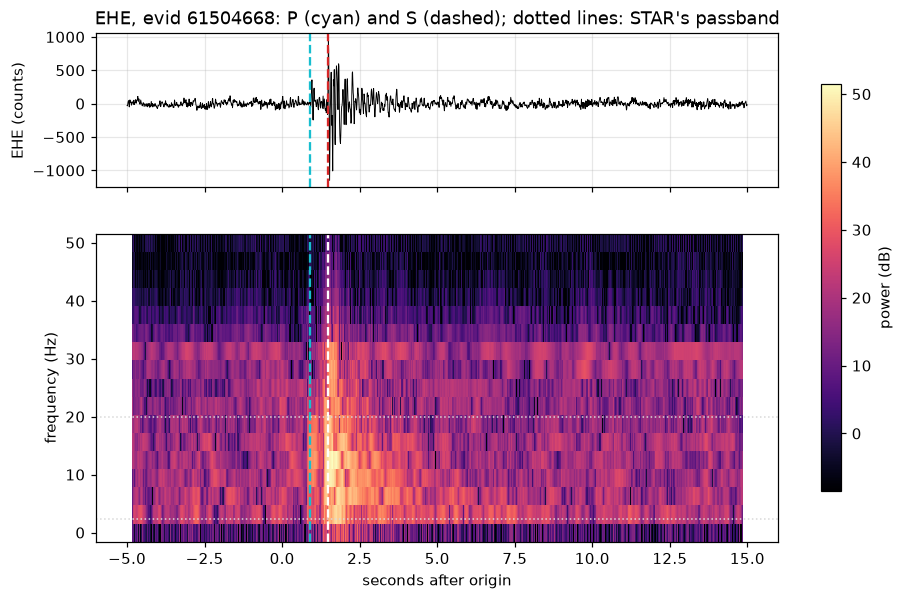

In [7]:
from scipy.signal import spectrogram

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
t_tr = tr.times(reftime=origin)
axes[0].plot(t_tr, tr.data, "k", lw=0.6); axes[0].set_ylabel("EHE (counts)")
f_sg, t_sg, S = spectrogram(tr.data.astype(float), fs=fs, nperseg=32, noverlap=29, scaling="spectrum")
t_sg = t_sg + (tr.stats.starttime - origin)          # seconds after origin
pc = axes[1].pcolormesh(t_sg, f_sg, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma",
                        vmin=np.percentile(10 * np.log10(S + 1e-12), 5))
fig.colorbar(pc, ax=axes, label="power (dB)", shrink=0.8, location="right")
for ax in axes:
    ax.axvline(p_time - origin, color="tab:cyan", ls="--"); ax.axvline(s_time - origin, color="w" if ax is axes[1] else "tab:red", ls="--")
for fe in (f_lo, f_hi):
    axes[1].axhline(fe, color="0.85", ls=":", lw=1)
axes[1].set_ylabel("frequency (Hz)"); axes[1].set_xlabel("seconds after origin"); axes[1].grid(False)
axes[0].set_title("EHE, evid 61504668: P (cyan) and S (dashed); dotted lines: STAR's passband")

- **Before P** (the first 5 s): a steady band of noise up to about 33 Hz and almost nothing above about 35 Hz. That upper edge is the instrument, not the Earth: by 35 Hz STAR's response is 20 times below its peak (section 1).
- **P** (cyan): a clear but modest brightening between about 5 and 30 Hz, weaker than S. E is a horizontal channel, but this event's ray reaches STAR about 30 degrees from vertical (its **incidence angle**) and from the east, so part of the P motion is on E.
- **S** (dashed): the brightest part of the picture, a burst from about 1.5 to 2.5 s after the origin, reaching up to the instrument's edge and strongest between about 3 and 15 Hz.
- **Coda**: after about 2.5 s the energy fades back into the noise over a few seconds, and the high frequencies go first, leaving 2 to 10 Hz. That is attenuation and scattering, the path of section 1, acting on the longer paths of the scattered waves.

The spectrum says *which* frequencies the S wave has; the spectrogram also says *when*. That is why the filter band and the analysis windows have to be chosen together.

## 4. Bandpass filtering

A **filter** multiplies each frequency by a set factor, its **gain**. A **bandpass** filter keeps the frequencies between two **corner frequencies** (the same name as the earthquake's corner frequency in section 1, but a different thing) and suppresses the rest. ObsPy's `filter("bandpass", ...)` builds a **Butterworth** filter, the design that is as flat as possible inside the band. Its `corners` argument is the filter's order: more corners, steeper sides.

There are two ways to apply a filter. A **causal** filter runs forwards in time, like any physical system, so its output depends only on the past, and it delays the signal (by an amount that depends on frequency). A **zero-phase** filter runs the same filter forwards and then backwards, so the delays cancel (and the gain is squared); the price is that a little energy leaks to *earlier* times. When the quantity you measure is a delay of a few hundredths of a second, that choice matters. For each band, the pipeline's filter bank (section 6) detrends, applies a 5 percent Hann taper, and runs a 2-corner causal bandpass (`sws_functions.try_filters`). Exercise 1 measures what the causal delay does to the S wave.

Top: the S and pre-event noise spectra of section 2. Bottom: the gain of three bandpass filters with 2 corners, as the pipeline uses them.

 1-5  Hz: gain 0.18 at half the lower corner, 0.17 at 10 Hz
 5-15 Hz: gain 0.14 at half the lower corner, 0.07 at 30 Hz
10-30 Hz: gain 0.15 at half the lower corner, 0.00 at 49 Hz


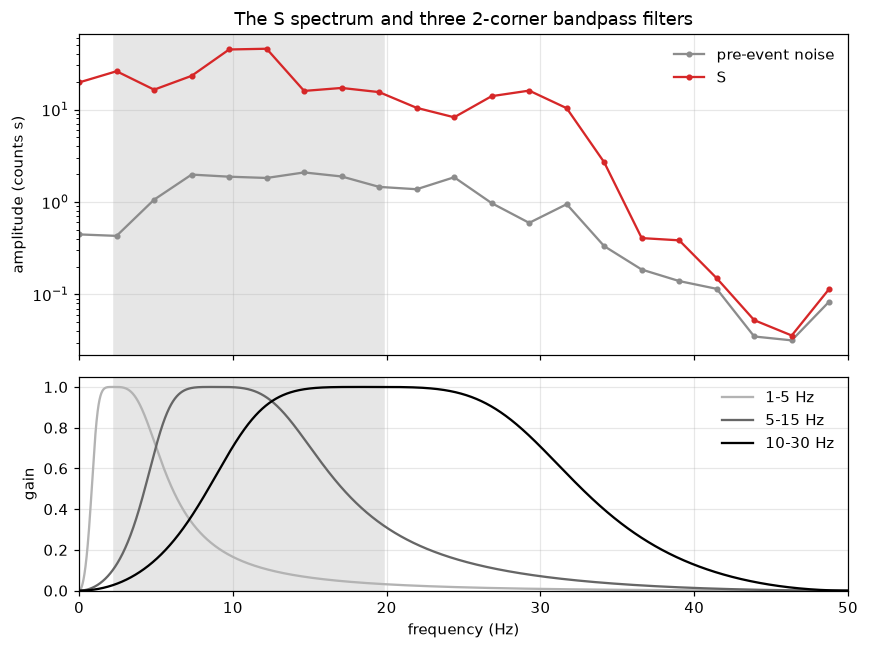

In [8]:
from scipy.signal import iirfilter, sosfreqz
bands = [(1, 5), (5, 15), (10, 30)]
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for name in ("pre-event noise", "S"):
    ax0.semilogy(freqs, spectra[name], color=colors[name], lw=1.5, marker="o", ms=3, label=name)
ax0.set_ylabel("amplitude (counts s)"); ax0.legend(frameon=False)
for (lo, hi), c in zip(bands, ["0.7", "0.4", "k"]):
    sos = iirfilter(2, [lo / (fs / 2), hi / (fs / 2)], btype="band", ftype="butter", output="sos")   # what ObsPy builds
    w, h = sosfreqz(sos, worN=4096, fs=fs)
    ax1.plot(w, np.abs(h), color=c, lw=1.5, label=f"{lo}-{hi} Hz")
    print(f"{lo:>2}-{hi:<2} Hz: gain {np.abs(h[np.argmin(np.abs(w - lo / 2))]):.2f} at half the lower corner, "
          f"{np.abs(h[np.argmin(np.abs(w - min(2 * hi, 49)))]):.2f} at {min(2 * hi, 49)} Hz")
for ax in (ax0, ax1):
    ax.axvspan(f_lo, f_hi, color="0.9", zorder=0)
ax1.set(xlabel="frequency (Hz)", ylabel="gain", xlim=(0, 50), ylim=(0, 1.05)); ax1.legend(frameon=False)
ax0.set_title("The S spectrum and three 2-corner bandpass filters")
plt.tight_layout()

With only 2 corners the sides are gentle: each filter still passes 14 to 18 percent of the amplitude at half its lower corner, and the 1-5 Hz filter passes 17 percent at 10 Hz. So "1-5 Hz" does not mean that nothing above 5 Hz gets through; it means that frequencies above 5 Hz are progressively weakened. Against the spectrum, 1-5 Hz keeps the low end, where the geophone is losing sensitivity; 10-30 Hz keeps the top, where the instrument cuts off; 5-15 Hz keeps the middle, where S is strongest. Here is the same S wave through each (zero-phase, so the arrivals stay at the picks):

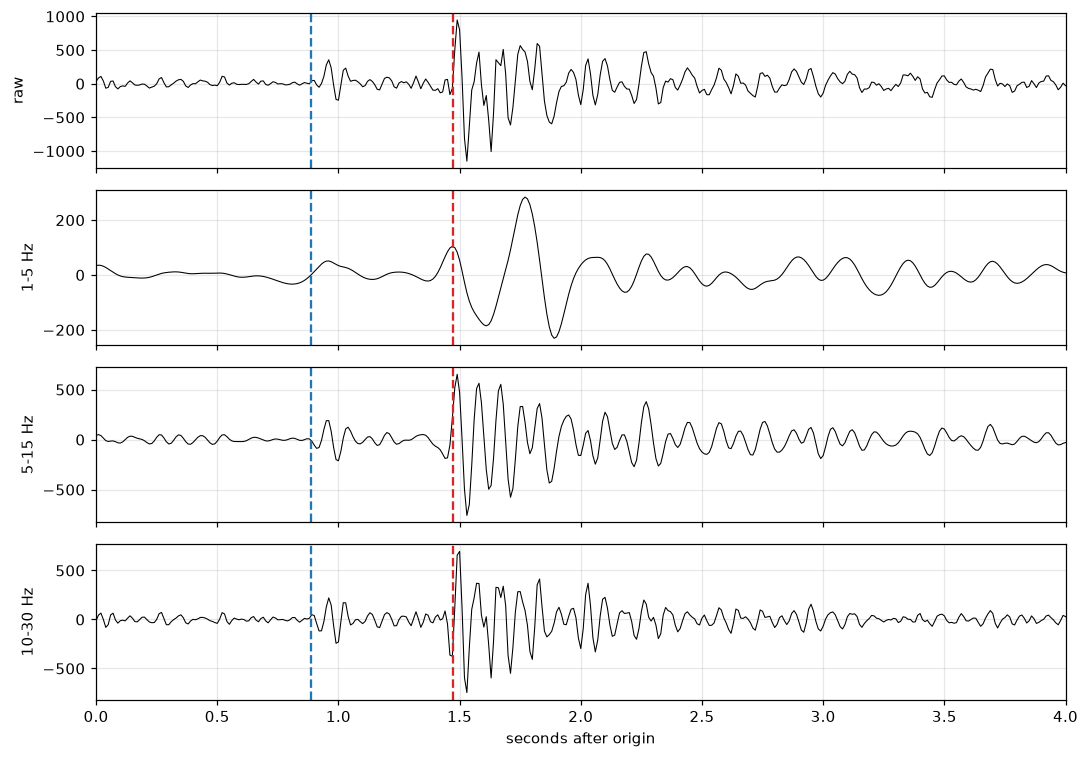

In [9]:
bands = [(1, 5), (5, 15), (10, 30)]
fig, axes = plt.subplots(len(bands) + 1, 1, figsize=(10, 7), sharex=True)
t = tr.times(reftime=origin)
axes[0].plot(t, tr.data, "k", lw=0.7); axes[0].set_ylabel("raw")
for ax, (lo, hi) in zip(axes[1:], bands):
    f = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=2, zerophase=True)
    ax.plot(t, f.data, "k", lw=0.7); ax.set_ylabel(f"{lo}-{hi} Hz")
for ax in axes:
    ax.axvline(p_time - origin, color="tab:blue", ls="--"); ax.axvline(s_time - origin, color="tab:red", ls="--")
axes[-1].set_xlabel("seconds after origin"); axes[-1].set_xlim(0, 4)
plt.tight_layout()

Through 1-5 Hz the S wave is one or two broad swings about 0.3 s long, and P has almost vanished. Through 5-15 Hz and 10-30 Hz it is a burst of sharp cycles about 0.1 s and 0.05 s long, and P shows clearly. The same earthquake gives quite different seismograms in different bands, and each one hands the splitting measurement a different wave to work on. Choosing among them is the filter bank's job (section 6).

## 5. Signal-to-noise ratio, defined precisely

The **signal-to-noise ratio** (SNR) says how much larger the wave we want is than everything else. It means nothing until you say which windows and which statistic. The pipeline's definition, on a trace already filtered to one band (`sws_functions._s_wave_snr_prefiltered`, as in MFAST):

- **signal**: the mean absolute amplitude from the S pick to 0.2 s after it (or to about two dominant periods after it, if that is shorter);
- **noise**: the mean absolute amplitude from 0.4 s before the S pick to the S pick, but never starting earlier than halfway between P and S;
- SNR = signal / noise, computed on N and on E and averaged.

At STAR, S-P is about 0.6 s, so the halfway point is 0.3 s before S and the whole noise window lies in the P coda. The cell filters our event to 5-10 Hz the way the filter bank does, computes the SNR by hand from the definition above, and checks it against the pipeline's function.

noise window -0.29 to 0 s from the S pick, signal window 0 to +0.20 s
SNR by hand 13.996, pipeline 13.996


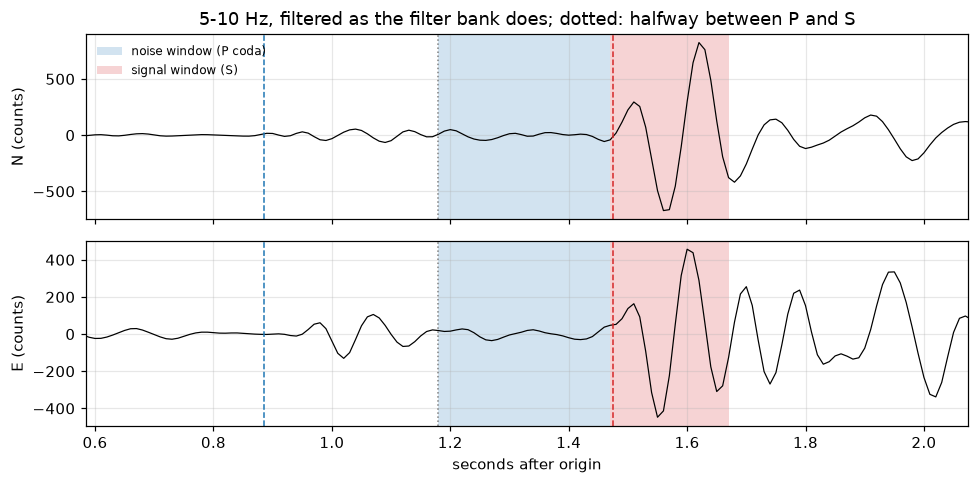

In [10]:
from rainier_sws import sws_functions as swsf
st5 = ev.copy().detrend("linear").taper(max_percentage=0.05, type="hann")
st5.filter("bandpass", freqmin=5, freqmax=10, corners=2)         # as try_filters does, in one of its bands
snr_pipe, T_pipe = swsf._s_wave_snr_prefiltered(st5, p_time, s_time)

def snr_windows(p_off, s_off, T, fs):
    """The pipeline's SNR windows, in samples: noise [n0, s], signal [s, s1)."""
    p, s = round(p_off * fs), round(s_off * fs)
    n0 = max(round((s_off - 0.4) * fs), round(p + (s - p) / 2))                  # not before the P-S midpoint
    s1 = min(round((s_off + 0.2) * fs), round(round((s_off - 0.02) * fs) + 2 * T))  # at most about 2 periods
    return n0, s, s1

n0, s_i, s1 = snr_windows(p_off, s_off, T_pipe, fs)
horiz5 = [st5.select(channel=f"??{c}")[0] for c in "NE"]
snr_hand = np.mean([np.abs(h.data[s_i:s1]).mean() / np.abs(h.data[n0:s_i + 1]).mean() for h in horiz5])
print(f"noise window {(n0 - s_i) / fs:+.2f} to 0 s from the S pick, signal window 0 to {(s1 - s_i) / fs:+.2f} s")
print(f"SNR by hand {snr_hand:.3f}, pipeline {snr_pipe:.3f}")

fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
t5 = st5[0].times() + t_start
for ax, h, c in zip(axes, horiz5, "NE"):
    ax.plot(t5, h.data, "k", lw=0.8)
    ax.axvspan(t5[n0], t5[s_i], color="tab:blue", alpha=0.2, lw=0, label="noise window (P coda)")
    ax.axvspan(t5[s_i], t5[s1], color="tab:red", alpha=0.2, lw=0, label="signal window (S)")
    ax.axvline(p_time - origin, color="tab:blue", ls="--", lw=1); ax.axvline(s_time - origin, color="tab:red", ls="--", lw=1)
    ax.axvline(t5[round(p_off * fs + (s_off - p_off) * fs / 2)], color="0.5", ls=":", lw=1)
    ax.set_ylabel(f"{c} (counts)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
axes[0].set_title("5-10 Hz, filtered as the filter bank does; dotted: halfway between P and S")
axes[1].set(xlim=(p_time - origin - 0.3, s_time - origin + 0.6), xlabel="seconds after origin")
plt.tight_layout()

The noise window (blue) is not noise in the sense of section 1: it is the tail of the P wave. So the pipeline's SNR asks "how much bigger is S than the P coda just before it?". That is not a bad question for splitting, because P coda that is still arriving during the S window adds motion that is not part of the S wave and can bias the measurement. But it is a different question from "does S stand out from the background?". Exercise 2 asks which question the SNR gate answers across all STAR events.

## 6. The filter bank: letting the data choose the band

Rather than use one band for all 900 events, the pipeline tries 14 candidate bands and keeps, for each event, the one where the SNR of section 5 is highest. A set of filters applied side by side like this is a **filter bank**. The bands come from **MFAST** (Savage et al., 2010), the automatic splitting code whose quality control the research pipeline follows. Choosing per event adapts to each earthquake, but the choice is made by an SNR estimate that is itself noisy. Left: each band's SNR for our event. Right: the frequencies each band keeps.

chosen band: (5.0, 10.0)  SNR: 14.0  dominant period (samples): 11.323076923076924
5-10 Hz    14.0
5-15 Hz    10.7
3-15 Hz    10.1


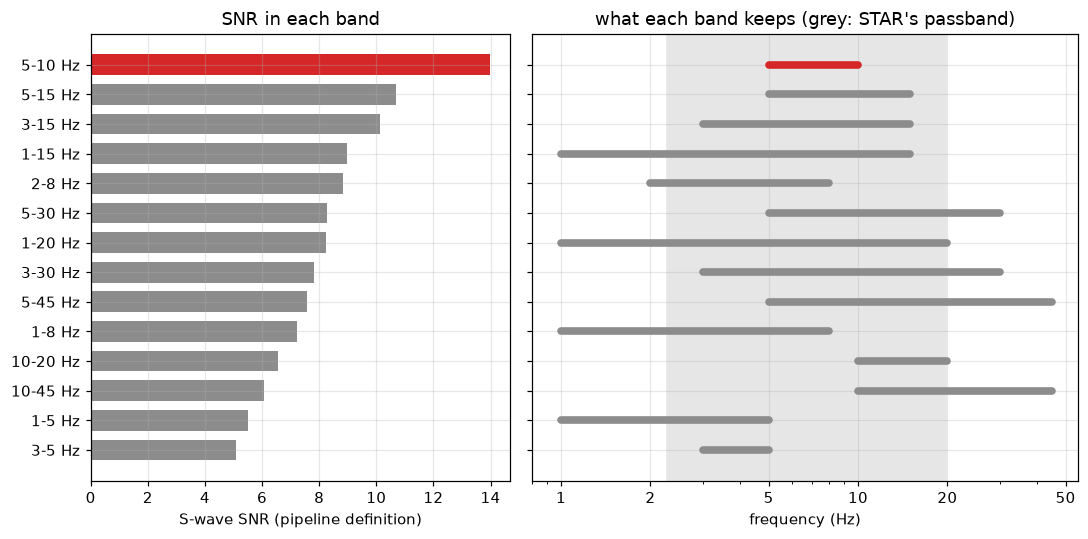

In [11]:
band, best_stream, snr, domp, snr_by_band = swsf.try_filters(ev.copy(), p_time, s_time)
print("chosen band:", band, " SNR:", round(snr, 2), " dominant period (samples):", domp)
print(pd.Series({f"{lo:g}-{hi:g} Hz": v for (lo, hi), v in snr_by_band.items()}).sort_values(ascending=False).head(3).round(1).to_string())
order = sorted(snr_by_band, key=snr_by_band.get)                 # lowest SNR at the bottom
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 5), sharey=True, gridspec_kw={"width_ratios": [1, 1.3]})
for i, b in enumerate(order):
    c = "tab:red" if b == band else "0.55"
    ax0.barh(i, snr_by_band[b], color=c, height=0.7)
    ax1.plot(b, [i, i], color=c, lw=5, solid_capstyle="round")
ax0.set(yticks=range(len(order)), yticklabels=[f"{lo:g}-{hi:g} Hz" for lo, hi in order],
        xlabel="S-wave SNR (pipeline definition)", title="SNR in each band")
ax1.axvspan(f_lo, f_hi, color="0.9", zorder=0)
ax1.set(xscale="log", xlim=(0.8, 55), xlabel="frequency (Hz)", title="what each band keeps (grey: STAR's passband)")
plain_ticks(ax1, [1, 2, 5, 10, 20, 50])
plt.tight_layout()

For this event 5-10 Hz wins with an SNR of 14, ahead of 5-15 Hz and 3-15 Hz (about 10.7 and 10.1). Several bands are close to the top: if the second-best band had been chosen, would the splitting answer change? That is exactly the kind of question notebook 07 asks, and the reason the band is recorded in every results row (`filter_band`).

The right panel also shows how the bank fits this station. The bands that reach 30 or 45 Hz extend into frequencies the instrument has mostly removed, so at STAR they differ less from their narrower neighbours than their labels suggest; the bands that start at 1 Hz begin below the geophone's natural frequency. The same 14 bands are used at every station, whatever its instrument.

## 7. Dominant period

The **period** of a wave is the time of one cycle, 1 / frequency. The **dominant period** $T$ of the S wave is the period of its strongest frequency. Splitting delays are compared with it: a delay longer than half a period is almost certainly a **cycle skip**, in which the measurement has lined up the slow wave with the wrong cycle of the fast one (notebook 04 shows one). The pipeline estimates the dominant period from the filtered S window with a spectrum (Baillard et al., 2014, as implemented in SWSPy), separately on N and E in a window from 0.1 s before S to 0.3 s after, and averages the two (`_s_wave_snr_prefiltered` in `sws_functions.py`). Done that way it reproduces the number the filter bank printed in section 6; on one channel or a different window it would not.

In [12]:
from swspy.splitting.split_windowcheck import get_dominant_period_baillard
periods = {}
for comp in "NE":
    seg = window(best_stream.select(channel=f"??{comp}")[0], s_off - 0.1, s_off + 0.3)
    periods[comp], _ = get_dominant_period_baillard(seg, fs)   # returns (period in samples, frequency in Hz)
T_samples = np.mean(list(periods.values()))
print("per channel (samples):", {k: round(v, 1) for k, v in periods.items()})
print(f"dominant period = {T_samples:.1f} samples = {T_samples / fs:.3f} s  ->  dominant frequency {fs / T_samples:.1f} Hz"
      f"  (filter bank in section 6: {domp:.1f} samples)")
print(f"half-period cycle-skip limit on dt = {T_samples / fs / 2:.3f} s")

per channel (samples): {'N': 12.8, 'E': 9.8}
dominant period = 11.3 samples = 0.113 s  ->  dominant frequency 8.8 Hz  (filter bank in section 6: 11.3 samples)
half-period cycle-skip limit on dt = 0.057 s


So for this event, in its chosen band, the post-processing filter would reject any delay above 0.057 s as a likely cycle skip. That limit comes from the band as much as from the earthquake; exercise 4 shows how much.

## 8. What this means for splitting

Notebook 04 builds the measurement; here is just enough to see why everything above matters. In **shear-wave splitting**, an S wave entering rock with aligned cracks splits into two S waves polarized at right angles: a **fast** wave shaking along the cracks and a **slow** wave shaking across them. The slow wave arrives a time **dt** later, and the fast wave's direction is **phi**. Both waves are recorded on the two horizontal components, so the measurement is a comparison of N and E in a short window around S.

The figure puts every timescale in this lesson on one axis. Bars span the middle 80 percent of STAR's events (10th to 90th percentile), dots mark the median, from the corrected-component results (`oriented=True`, notebook 07).

194 filtered STAR events: dt 0.02 to 0.08 s, median 0.06 s; median dominant period 0.183 s


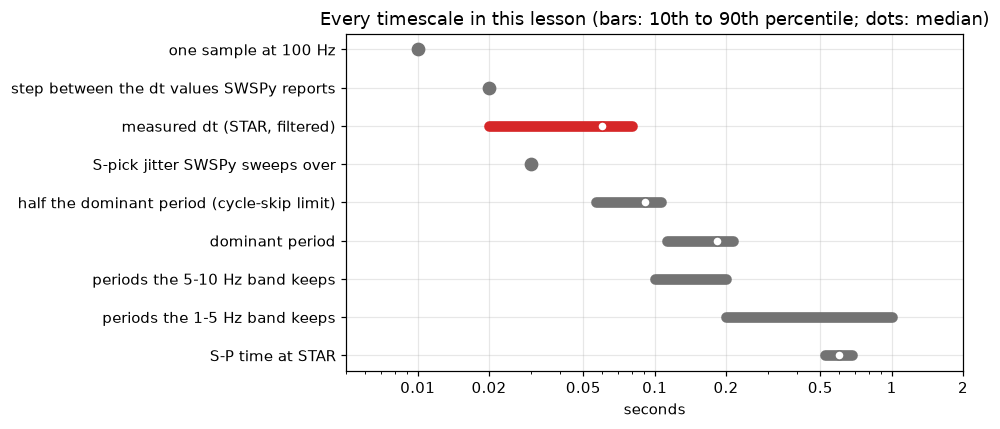

In [13]:
res_o = pd.read_csv(paths.station_results_csv("STAR", oriented=True))
ok = quality.successful(res_o)
good = quality.post_filtered(res_o)
sp = (cat.s_time - cat.p_time).dt.total_seconds()
q = lambda s: (s.quantile(0.1), s.quantile(0.9), s.median())
scales = [  # label, low, high, median (None: a single value or a fixed range)
    ("one sample at 100 Hz", 1 / fs, 1 / fs, None),
    ("step between the dt values SWSPy reports", 2 / fs, 2 / fs, None),
    ("measured dt (STAR, filtered)", *q(good.dt)),
    ("S-pick jitter SWSPy sweeps over", measure.SwsParams().s_pick_uncertainty, measure.SwsParams().s_pick_uncertainty, None),
    ("half the dominant period (cycle-skip limit)", *q(ok.dominant_period / 2)),
    ("dominant period", *q(ok.dominant_period)),
    ("periods the 5-10 Hz band keeps", 0.1, 0.2, None),
    ("periods the 1-5 Hz band keeps", 0.2, 1.0, None),
    ("S-P time at STAR", *q(sp)),
]
fig, ax = plt.subplots(figsize=(9, 4))
for i, (label, lo, hi, mid) in enumerate(scales[::-1]):
    c = "tab:red" if label.startswith("measured dt") else "0.45"
    if lo == hi:
        ax.plot(lo, i, "o", color=c, ms=8)
    else:
        ax.plot([lo, hi], [i, i], color=c, lw=7, solid_capstyle="round")
    if mid is not None:
        ax.plot(mid, i, "o", color="w", mec=c, ms=6)
ax.set(xscale="log", xlim=(0.005, 2), yticks=range(len(scales)), yticklabels=[s[0] for s in scales[::-1]],
       xlabel="seconds", title="Every timescale in this lesson (bars: 10th to 90th percentile; dots: median)")
plain_ticks(ax, [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2])
plt.tight_layout()
print(f"{len(good)} filtered STAR events: dt {good.dt.quantile(0.1):.2f} to {good.dt.quantile(0.9):.2f} s, "
      f"median {good.dt.median():.2f} s; median dominant period {ok.dominant_period.median():.3f} s")

What the figure says:

- **dt is a few samples.** The filtered delays are 0.02 to 0.08 s, 2 to 8 samples. SWSPy tries each delay by shifting the two components half of it each, rounded down to whole samples (`_phi_dt_grid_search` in `swspy/splitting/split_windowcheck.py`), so at 100 Hz only even numbers of samples are tried and dt comes in steps of 0.02 s. Anything that moves one horizontal against the other by a sample or two, or reshapes the S wave, competes with the signal.
- **dt is the size of the timing choices.** It matches the S-pick jitter SWSPy sweeps over (0.03 s) and the causal filter's delay of the S wave (about 0.04 s, exercise 1). Neither shifts N against E, but both move the S wave relative to the windows that are placed from the pick.
- **dt is a small fraction of a period.** Through 1-5 Hz, the band most STAR events get, a 0.05 s delay is a twentieth of a cycle at 1 Hz and a quarter of one at 5 Hz. The measurement can still find it, because it uses the whole shape of the wave rather than one peak, but the shorter the period, the more clearly a delay shows. At the other end, the cycle-skip limit (half the dominant period) overlaps the measured delays, so the larger delays are close to being rejected (exercise 4).
- **Splitting may depend on frequency.** When cracks hold fluid, how much a shear wave splits can depend on its frequency. In Chapman's (2003) model, fluid flowing between cracks and pores makes the anisotropy frequency-dependent, with the size of the fractures controlling how; Marson-Pidgeon and Savage (1997) measured delays that differed with the waves' dominant frequency. Rainier's fracture network carries hydrothermal fluid, so this is a live possibility here. And the filter bank picks a band per event: if the mix of bands changes during the swarm, dt can change because the band changed rather than the rock. Exercise 3 checks whether it does.

## 9. Glossary

| term | meaning | section |
| --- | --- | --- |
| attenuation | loss of wave energy to friction and fluid flow in the rock; stronger at high frequency | 1 |
| bandpass filter | keeps the frequencies between two corner frequencies, suppresses the rest | 4 |
| Butterworth filter | the filter design ObsPy uses: as flat as possible inside the band | 4 |
| causal filter | runs forwards in time; output depends only on the past; delays the signal | 4 |
| coda | the tail of scattered waves after an arrival (P coda: after P, before S) | 1, 2 |
| corner frequency (earthquake) | $f_c$: where the source's displacement spectrum turns from flat to falling; higher for smaller earthquakes | 1 |
| corner frequency (filter) | the edges of a filter's band; ObsPy's `corners` argument is something else, the order | 4 |
| counts | the digitizer's integer output; proportional to ground velocity only through the instrument response | 1 |
| cycle skip | the slow wave lined up with the wrong cycle of the fast one, so dt is off by about a period | 7 |
| detrend | remove a trace's mean and straight-line trend | 2 |
| dominant period $T$ | the period of the strongest frequency in the S window | 7 |
| dt, phi | splitting delay time, and the direction of the fast wave (clockwise from north) | 8 |
| fast and slow wave | the two S waves a split produces, shaking along and across the cracks | 8 |
| filter bank | a set of filters applied side by side; the pipeline keeps the one with the best SNR | 6 |
| Fourier amplitude spectrum | how much of each frequency a window of a trace contains | 2 |
| frequency resolution | the spacing between the frequencies a spectrum can separate: 1 / window length | 2 |
| gain | the factor a filter or instrument multiplies one frequency by | 4 |
| geophone | a velocity sensor: a coil on a spring moving past a magnet | 1 |
| incidence angle | the angle between the incoming ray and the vertical | 3 |
| instrument response | output counts per unit ground velocity, as a function of frequency; amplitude and phase | 1 |
| MFAST | automatic splitting software (Savage et al., 2010); source of the filter bank and quality control | 6 |
| microseism | ground motion driven by ocean waves, 0.05 to 0.5 Hz | 1 |
| moment magnitude $M_w$ | magnitude computed from the seismic moment | 1 |
| natural frequency | the frequency at which the sensor's mass on its spring resonates; 2 Hz at STAR | 1 |
| Nyquist frequency | half the sampling rate; the highest frequency a sampled trace can hold (50 Hz) | 2 |
| passband | the frequencies an instrument (or filter) passes nearly unchanged; within 3 dB of the peak | 1 |
| period | the time of one cycle, 1 / frequency | 7 |
| phase response | how far an instrument or filter shifts each frequency, as a fraction of a cycle | 1 |
| quality factor $Q$ | inverse measure of attenuation: each cycle loses about $2\pi/Q$ of its energy | 1 |
| scattering | waves bounced off small-scale heterogeneity, out of the direct wave and into the coda | 1 |
| seismic moment $M_0$ | rigidity × fault area × average slip, in N m: the size of an earthquake | 1 |
| shear-wave splitting | an S wave split into a fast and a slow wave by aligned cracks | 8 |
| signal-to-noise ratio (SNR) | amplitude of the wanted wave over that of everything else, in stated windows | 5 |
| spectrogram | short spectra side by side in time | 3 |
| StationXML | the standard format for station metadata, including the instrument response | 1 |
| stress drop $\Delta\sigma$ | how much the shear stress on the fault fell in the earthquake | 1 |
| $t^*$ | travel time / $Q$; attenuation removes a factor $\exp(-\pi f t^*)$ | 1 |
| taper | multiply a window by a smooth bump that is zero at both ends | 2 |
| zero-phase filter | the filter run forwards and backwards; no delay, but leaks a little energy to earlier times | 4 |

References in this notebook: Brune, J.N. (1970), *Tectonic stress and the spectra of seismic shear waves from earthquakes*, JGR 75, 4997-5009. Hanks, T.C. & Kanamori, H. (1979), *A moment magnitude scale*, JGR 84, 2348-2350. Savage, M.K. et al. (2010), JGR 115, B12321 (MFAST). Baillard, C. et al. (2014), BSSA 104, 394-409 (the dominant period). Chapman, M. (2003), *Frequency-dependent anisotropy due to meso-scale fractures in the presence of equant porosity*, Geophys. Prospect. 51, 369-379, doi:10.1046/j.1365-2478.2003.00384.x. Marson-Pidgeon, K. & Savage, M.K. (1997), *Frequency-dependent anisotropy in Wellington, New Zealand*, GRL 24, doi:10.1029/97GL03274.

## 10. Exercises

Each one asks a question the project needs answered, using the tools of this lesson.

1. **The pipeline's filter moves the S wave.** The filter bank uses 2 corners and ObsPy's default `zerophase=False`. Filter `tr` (east) to 5-15 Hz that way and with `zerophase=True`, and measure how much later the S wave appears relative to the pick in the causal version: by eye first, then with something more precise. Try 4 corners as well. Every window in the pipeline (SNR, dominant period, SWSPy's analysis windows) is placed from the pick. Does the shift matter for dt? For the windows?
2. **What does the SNR gate measure at STAR?** Section 5 showed that at STAR the pipeline's noise window is P coda. For every STAR event, filter the waveforms to the band in its `filter_band` (in `res_o`, the corrected-component results) the way the filter bank does, and compute two SNRs: the pipeline's, and one against pre-event noise (the same window length, ending 0.1 s before P; `snr_windows` from section 5 helps). How many events fall below an SNR of 2 under each? Plot both against magnitude. Which SNR measures "S stands out from the background", and what does the other one measure?
3. **Which band wins, and does that change?** Run the filter bank on five more events from `cat` and look at the runner-up bands. Then, for every event, tabulate the chosen band from `res_o` and from the archived results file (`paths.station_results_csv("STAR")`). Does the choice depend on magnitude? Does it change through the swarm (try 8 July, 9-10 July, 11-14 July, 15-21 July and later)? What would a change mean for a plot of dt against time?
4. **The dominant period and the cycle-skip cut.** The post-processing filter rejects measurements with dt larger than half the dominant period. From the successful measurements in `res_o`, find what sets the dominant period: the magnitude, or the chosen band? How many measurements fail *only* this cut, and in which bands? (`dataclasses.replace(quality.DEFAULT_POST, dt_period_fraction=np.inf)` switches the cut off.)
5. (Stretch) **Could the instrument fake a delay?** Section 1 relied on both horizontals having the same response. Real geophones differ a little. From the first stage of `resp` (the geophone: natural frequency 2 Hz, damping from its poles), compute the phase difference between two geophones whose natural frequencies differ by 1, 5 and 10 percent, and turn it into a time delay at 1, 3, 5 and 9 Hz. Compare with the measured dt in section 8.

Next: `04_what_is_shear_wave_splitting.ipynb`, where the physics of the split finally shows up.

## 11. Example solutions

One way to do each exercise. Try them yourself first; the commentary is about the figure-3 event and the events sampled here.

### Exercise 1: the pipeline's filter moves the S wave

"By eye" is hard at 0.01 s per sample, so measure it as well. Cross-correlating the filtered wiggles is ambiguous (a shift of one whole period, about 0.1 s here, matches almost as well as no shift), so compare **envelopes** instead: the smooth outline of a wave, the magnitude of its analytic signal from the Hilbert transform (`scipy.signal.hilbert`). Two measures: the lag that best aligns the causal envelope with the zero-phase one, and the time at which the envelope first reaches half its maximum. Do it for the 2-corner filter the pipeline's filter bank uses and for a 4-corner one.

2 corners, zero-phase                            envelope lag vs zero-phase   0 ms,  onset   +0 ms from the S pick
4 corners, causal                                envelope lag vs zero-phase  80 ms,  onset  +80 ms from the S pick
2 corners, causal (the pipeline's filter bank)   envelope lag vs zero-phase  40 ms,  onset  +40 ms from the S pick
N relative to E around S, zero-phase:  10 ms
N relative to E around S, causal    :  10 ms


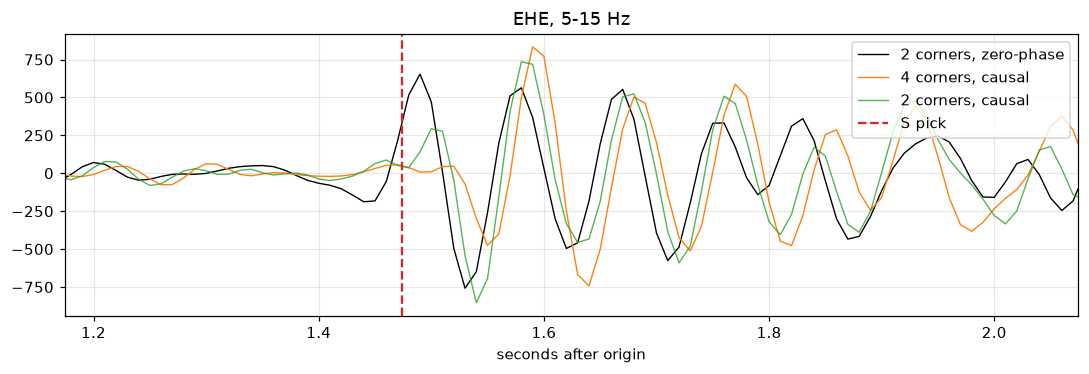

In [14]:
from scipy.signal import correlate, hilbert

def envelope(x):
    return np.abs(hilbert(x - x.mean()))

def envelope_lag(a, b, max_lag=0.1):
    """Time (s) by which the envelope of a lags the envelope of b."""
    ea, eb = envelope(a), envelope(b)
    cc = correlate(ea - ea.mean(), eb - eb.mean(), mode="full")
    lags = np.arange(-len(eb) + 1, len(ea)) / fs
    keep = np.abs(lags) <= max_lag
    return lags[keep][np.argmax(cc[keep])]

lo, hi = 5, 15
s0, s1 = s_off - 0.3, s_off + 0.6                  # window around S, seconds after trace start
def onset(f):
    """Seconds after the S pick at which the envelope first reaches half its maximum."""
    e = envelope(window(f, s0, s1))
    return np.argmax(e > 0.5 * e.max()) / fs + s0 - s_off

zero = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=2, zerophase=True)
causal4 = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=4, zerophase=False)
causal2 = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, corners=2, zerophase=False)
for name, f in [("2 corners, zero-phase", zero), ("4 corners, causal", causal4),
                ("2 corners, causal (the pipeline's filter bank)", causal2)]:
    print(f"{name:48s} envelope lag vs zero-phase {envelope_lag(window(f, s0, s1), window(zero, s0, s1)) * 1000:3.0f} ms,"
          f"  onset {onset(f) * 1000:+4.0f} ms from the S pick")

# the same causal filter on both horizontals: does the N-E relative timing change?
n_tr = ev.select(channel="??N")[0].copy().detrend("linear")
for name, kw in [("zero-phase", dict(corners=2, zerophase=True)), ("causal", dict(corners=4, zerophase=False))]:
    fn = n_tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, **kw)
    fe = tr.copy().filter("bandpass", freqmin=lo, freqmax=hi, **kw)
    a, b = window(fn, s0, s1), window(fe, s0, s1)
    cc = correlate(a - a.mean(), b - b.mean(), mode="full"); lags = np.arange(-len(b) + 1, len(a)) / fs
    keep = np.abs(lags) <= 0.05
    print(f"N relative to E around S, {name:10s}: {lags[keep][np.argmax(cc[keep])] * 1000:3.0f} ms")

fig, ax = plt.subplots(figsize=(10, 3.5))
t = tr.times(reftime=origin)
ax.plot(t, zero.data, "k", lw=0.9, label="2 corners, zero-phase")
ax.plot(t, causal4.data, "tab:orange", lw=0.9, label="4 corners, causal")
ax.plot(t, causal2.data, "tab:green", lw=0.9, alpha=0.8, label="2 corners, causal")
ax.axvline(s_time - origin, color="tab:red", ls="--", label="S pick")
ax.set_xlim(s_time - origin - 0.3, s_time - origin + 0.6); ax.set_xlabel("seconds after origin"); ax.legend(loc="upper right")
ax.set_title(f"EHE, {lo}-{hi} Hz")
plt.tight_layout()

**The shift.** The 2-corner causal filter the pipeline uses moves the S wave about 40 ms later, and a 4-corner causal filter about 80 ms (8 samples). The zero-phase filter does not shift it, but look at the black trace just before the pick: a small swing appears *before* the S onset, although here the envelope only reaches half height at the pick itself. A zero-phase filter is not causal; running it backwards smears a little energy to earlier times. Neither choice is free: causal filters delay, zero-phase filters leak backwards.

**Does it matter for splitting?** Less than you might think for dt, more than you might think for everything else:

- dt is a delay *between* two horizontal components, and both get the same filter, so a pure delay cancels. The filter also changes the shape of the wave, though, and the N-E lag around S moves by one sample (10 ms) between the zero-phase and causal versions here.
- Everything placed *from the pick* sees the S wave about 40 ms later than the pick says: the SNR windows, the dominant-period window and SWSPy's analysis windows. That is the same size as the S-pick jitter SWSPy sweeps over (section 8), and as the 0.03 s pick shift that flips Q_w for this event in notebook 07, section 6.

So the honest answer to "why zero-phase?" is that the pipeline does not use it, and whether it should is a fair question to raise with Michael, together with a measurement of how much it changes the results.

### Exercise 2: what the SNR gate measures at STAR

For every event with a chosen band, refilter it as the filter bank does, compute the pipeline's SNR (it should match `snr_horizontal` in the results file to rounding, which checks the recipe), and compute the same ratio against a pre-event noise window of the same length.

900 events; largest difference from the results file's snr_horizontal: 1.0e-13
SNR against the P coda (the pipeline)  median   7.2; below 2:  13; correlation of log SNR with magnitude -0.11
SNR against pre-event noise            median  35.8; below 2:   0; correlation of log SNR with magnitude +0.63
stages of the events below 2 against the P coda: {'fail_snr': 8, 'fail_clipped': 4, 'fail_incidence': 1}


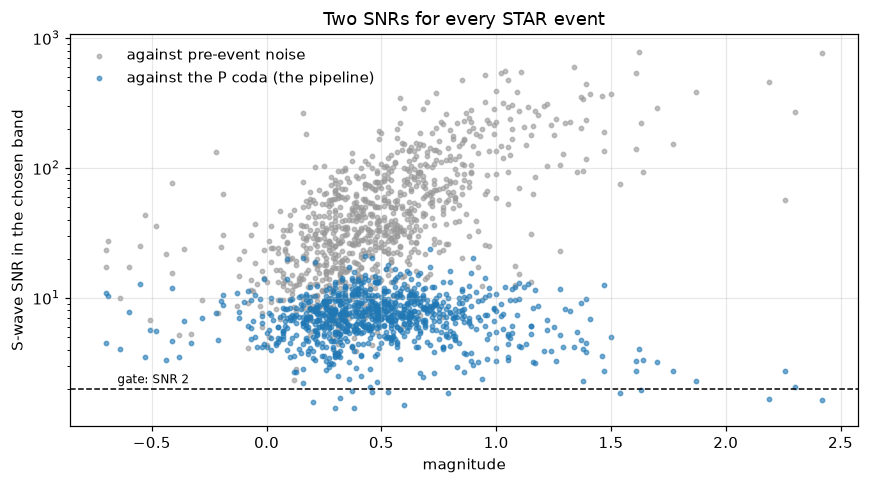

In [15]:
import ast
rows = []
for _, x in res_o.dropna(subset=["filter_band"]).iterrows():
    r = cat[cat.evid == x.evid].iloc[0]
    e = data.get_event_stream("STAR", r, allow_download=False)
    _, pt, st_, p_o, s_o = measure.pick_offsets(e, r)
    lo, hi = ast.literal_eval(x.filter_band)
    fst = e.copy().detrend("linear").taper(max_percentage=0.05, type="hann").filter("bandpass", freqmin=lo, freqmax=hi, corners=2)
    snr_coda, T = swsf._s_wave_snr_prefiltered(fst, pt, st_)
    n0_, s_, s1_ = snr_windows(p_o, s_o, T, fs)
    p_, n_ = round(p_o * fs), s_ - n0_                     # a noise window of the same length, ending 0.1 s before P
    snr_pre = np.mean([np.abs(h.data[s_:s1_]).mean() / np.abs(h.data[p_ - 10 - n_:p_ - 10 + 1]).mean()
                       for h in fst.select(channel="??[NE]")])
    rows.append(dict(evid=x.evid, M=r.event_magnitude, stage=x.stage, snr_file=x.snr_horizontal,
                     coda=snr_coda, pre_event=snr_pre))
gate = pd.DataFrame(rows)
print(f"{len(gate)} events; largest difference from the results file's snr_horizontal: {np.abs(gate.coda - gate.snr_file).max():.1e}")
for col, name in [("coda", "against the P coda (the pipeline)"), ("pre_event", "against pre-event noise")]:
    print(f"SNR {name:34s} median {gate[col].median():5.1f}; below 2: {(gate[col] < 2).sum():3d}; "
          f"correlation of log SNR with magnitude {np.corrcoef(gate.M, np.log10(gate[col]))[0, 1]:+.2f}")
print("stages of the events below 2 against the P coda:", gate[gate.coda < 2].stage.value_counts().to_dict())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(gate.M, gate.pre_event, s=8, color="0.6", alpha=0.6, label="against pre-event noise")
ax.scatter(gate.M, gate.coda, s=8, color="tab:blue", alpha=0.6, label="against the P coda (the pipeline)")
ax.axhline(2, color="k", lw=1, ls="--"); ax.text(-0.65, 2.2, "gate: SNR 2", fontsize=8)
ax.set(yscale="log", xlabel="magnitude", ylabel="S-wave SNR in the chosen band", title="Two SNRs for every STAR event")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

The recipe reproduces the pipeline's SNR to 1e-13, so the two numbers differ only in their noise windows, and they differ a lot:

- **Against pre-event noise** the median SNR is 36 and no event is below 2. It grows with magnitude (correlation +0.63), as a signal-to-background ratio should: bigger earthquakes stand further above a background that does not depend on them.
- **Against the P coda** (the pipeline's SNR) the median is 7 and 13 events are below 2: 8 that the pipeline stopped at this gate (`fail_snr`) and 5 it had already stopped at an earlier check. And it does not depend on magnitude at all (correlation -0.11). The P coda grows with the earthquake just as S does, so their ratio measures the *shape* of the seismogram, how much stronger S is than P on the horizontals, not the size of the earthquake.

So at STAR the SNR gate does not ask whether S stands out from the background (for every event in this catalog it does). It asks whether S stands out from the P coda. That is still worth asking for splitting (section 5), but a write-up should describe the gate that way, and the threshold of 2 has no special meaning for it. It removes few events here (8 of 900), so it hardly matters at STAR. At every station the pipeline's noise window lies between P and S; at a station farther away it sits later in a decaying P coda, so the same code is a somewhat different cut at each station, which is worth knowing before comparing stations.

### Exercise 3: which band wins, and does that change?

Five events, sampled with a fixed seed so the choice is repeatable, then every STAR event from both results files. The archived file predates STAR's orientation fix: its "horizontals" were the vertical and east records, so its bands were chosen on the wrong components.

In [16]:
cached = data.describe_cache("STAR").query("complete").evid
picked = []
for _, r in cat[cat.evid.isin(cached) & (cat.evid != row.evid)].sample(5, random_state=3).iterrows():
    e = data.get_event_stream("STAR", r, allow_download=False)
    _, pt, st_, _, _ = measure.pick_offsets(e, r)
    b, _, s, _, by_band = swsf.try_filters(e, pt, st_)
    ranked = pd.Series(by_band).dropna().sort_values(ascending=False)
    picked.append({"evid": r.evid, "M": r.event_magnitude, "chosen band": b, "SNR": round(s, 1),
                   "runner-up": ranked.index[1], "runner-up SNR": round(ranked.iloc[1], 1)})
print(pd.DataFrame(picked).to_string(index=False))

res = pd.read_csv(paths.station_results_csv("STAR"))
share = pd.DataFrame({"archived components": res.filter_band.value_counts(normalize=True),
                      "corrected components": res_o.filter_band.value_counts(normalize=True)}).mul(100).fillna(0).round(1)
print(f"\npercent of STAR events choosing each band ({res.filter_band.notna().sum()} and {res_o.filter_band.notna().sum()} events):")
print(share.sort_values("corrected components", ascending=False).to_string())

    evid    M chosen band  SNR   runner-up  runner-up SNR
62139482 0.65  (1.0, 5.0)  7.1 (5.0, 10.0)            6.9
62144602 1.87  (1.0, 5.0)  2.3  (1.0, 8.0)            1.8
62137262 0.42  (1.0, 5.0) 13.2  (2.0, 8.0)            9.3
62135552 0.57  (1.0, 5.0)  4.6  (1.0, 8.0)            3.5
62134552 0.17  (2.0, 8.0)  7.7  (1.0, 5.0)            7.1

percent of STAR events choosing each band (900 and 900 events):
              archived components  corrected components
filter_band                                            
(1.0, 5.0)                   42.6                  58.1
(5.0, 10.0)                   9.2                  14.9
(3.0, 5.0)                    7.2                  13.1
(2.0, 8.0)                    4.0                   6.9
(1.0, 8.0)                    6.4                   3.3
(10.0, 20.0)                  2.6                   0.8
(5.0, 15.0)                   4.9                   0.8
(1.0, 15.0)                   5.3                   0.6
(1.0, 20.0)                

For these five events the bank chose 1-5 Hz four times and 2-8 Hz once. The runner-up is often close (7.1 against 6.9, 7.7 against 7.1), and for 62139482 it is a very different band (5-10 Hz just behind 1-5 Hz), so the "best band" is often a near tie decided by a noisy SNR. Note 62144602: magnitude 1.9, the largest of the five, but its best SNR is 2.3, just above the gate of 2. Exercise 2 explains why size does not help this SNR.

On the corrected components, 1-5 Hz wins for 58 percent of all STAR events, 5-10 Hz for 15 percent and 3-5 Hz for 13 percent: three bands cover 86 percent. On the archived components the choice was spread much more widely (1-5 Hz 43 percent, and the broad and high bands such as 10-45 Hz and 1-15 Hz 5 to 7 percent each), because it was made on the vertical and east records. So the archived `filter_band` column should not be used for STAR. One band dominates, but a fixed band would still give up the best band for 42 percent of events, and 1-5 Hz is also the band with the longest periods (section 8). That trade-off between SNR and resolution is why the pipeline lets the data choose.

Now whether the choice depends on the earthquake's size, or changes through the swarm:

                N  share  median_M    se
swarm period                            
Jul 8         182   0.47      0.44  0.04
Jul 9-10      236   0.70      0.44  0.03
Jul 11-14     201   0.58      0.44  0.03
Jul 15-21     192   0.56      0.53  0.04
Jul 22 on      89   0.55      0.43  0.05 

               N  share  median_M    se
magnitude                              
below 0.25   193   0.60      0.15  0.04
0.25-0.5     313   0.55      0.37  0.03
0.5-0.75     228   0.58      0.61  0.03
0.75 and up  166   0.61      0.96  0.04 

8 July to 9-10 July: share of 1-5 Hz +0.24, 5.0 standard errors


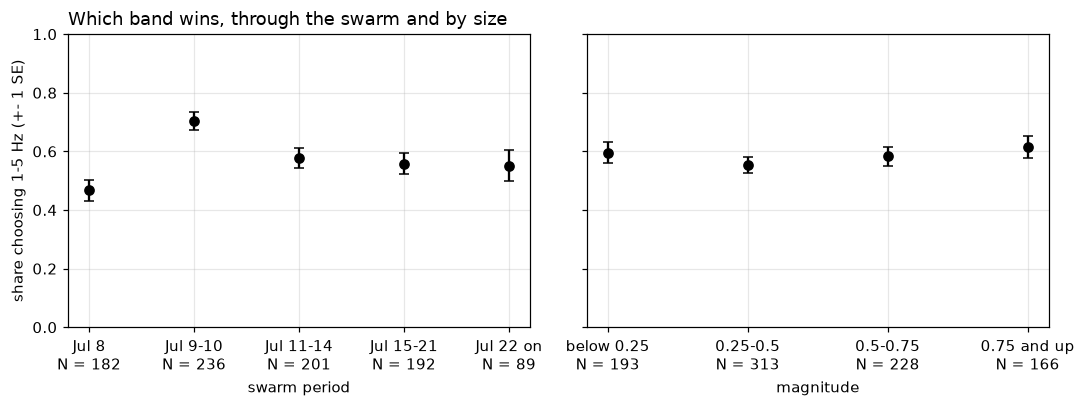

In [17]:
periods = ["Jul 8", "Jul 9-10", "Jul 11-14", "Jul 15-21", "Jul 22 on"]
mags = ["below 0.25", "0.25-0.5", "0.5-0.75", "0.75 and up"]
b = res_o.dropna(subset=["filter_band"]).merge(cat[["evid", "event_magnitude", "origin_time"]], on="evid")
b["low band"] = b.filter_band == "(1.0, 5.0)"
day = b.origin_time.dt.tz_convert(None).dt.floor("D")
b["swarm period"] = pd.Categorical(np.select([day < "2025-07-09", day < "2025-07-11", day < "2025-07-15", day < "2025-07-22"],
                                             periods[:4], periods[4]), periods)
b["magnitude"] = pd.cut(b.event_magnitude, [-1, 0.25, 0.5, 0.75, 3], labels=mags)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
groups = {}
for ax, by in zip(axes, ["swarm period", "magnitude"]):
    g = b.groupby(by, observed=True).agg(N=("low band", "size"), share=("low band", "mean"), median_M=("event_magnitude", "median"))
    g["se"] = np.sqrt(g.share * (1 - g.share) / g.N)                # binomial standard error
    print(g.round(2).to_string(), "\n")
    groups[by] = g
    ax.errorbar(range(len(g)), g.share, yerr=g.se, fmt="o", color="k", capsize=3)
    ax.set(xticks=range(len(g)), xticklabels=[f"{i}\nN = {n}" for i, n in zip(g.index, g.N)], xlabel=by, ylim=(0, 1))
axes[0].set_ylabel("share choosing 1-5 Hz (+- 1 SE)")
axes[0].set_title("Which band wins, through the swarm and by size", loc="left")
plt.tight_layout()
a, c = groups["swarm period"].loc["Jul 8"], groups["swarm period"].loc["Jul 9-10"]
print(f"8 July to 9-10 July: share of 1-5 Hz {c.share - a.share:+.2f}, {(c.share - a.share) / np.hypot(a.se, c.se):.1f} standard errors")

- **Magnitude:** the share of events choosing 1-5 Hz is flat, 55 to 61 percent in every magnitude bin, within about one standard error of each other. That is section 1's prediction: at STAR the shape of the spectrum is set by the path and the instrument, not by the size of the earthquake.
- **Time:** the share changes. On 8 July 47 ± 4 percent of events chose 1-5 Hz, on 9 and 10 July 70 ± 3 percent, about 5 standard errors more, and afterwards about 56 percent. The median magnitude is 0.44 in both of the first two periods, so the size of the earthquakes did not change.

What could change the band if not the size? Something about the path or the waves: where in the swarm the earthquakes were (the swarm moved; notebook 02, exercise 2), and so how much P coda and attenuation each path carries. Finding out is an afternoon's project.

What it means for dt against time: if splitting depends on frequency (section 8), a change in the band mix shows up as a change in dt even if the rock did not change. Before reading a trend in dt or phi across the swarm, check the band mix in the same time bins, or compare like with like (only the 1-5 Hz events, for example).

### Exercise 4: the dominant period and the cycle-skip cut

median dominant period (s) by magnitude: {'below 0.25': 0.183, '0.25-0.5': 0.178, '0.5-0.75': 0.183, '0.75 and up': 0.183}
                N  median_T  pass_filter  fail_only_cut  half T
filter_band                                                    
(1.0, 5.0)    383     0.190          136              6   0.095
(5.0, 10.0)   114     0.115           31              4   0.058
(3.0, 5.0)     68     0.198           10              1   0.099
(2.0, 8.0)     50     0.151            9              7   0.075
(1.0, 8.0)     18     0.178            3              2   0.089
(10.0, 20.0)    6     0.075            2              1   0.037

659 successful measurements: 194 pass the filter, 28 more would pass without the dt <= T/2 cut; 17% have dt > T/2


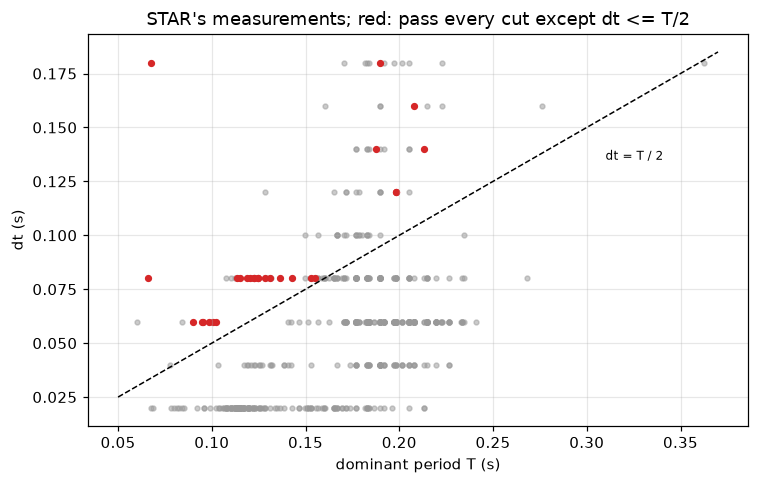

In [18]:
from dataclasses import replace
ok = quality.successful(res_o).merge(cat[["evid", "event_magnitude"]], on="evid")
ok["magnitude"] = pd.cut(ok.event_magnitude, [-1, 0.25, 0.5, 0.75, 3], labels=mags)
passes = quality.post_filter_mask(ok)
passes_without_cut = quality.post_filter_mask(ok, replace(quality.DEFAULT_POST, dt_period_fraction=np.inf))
ok["fails only dt <= T/2"] = passes_without_cut & ~passes
print("median dominant period (s) by magnitude:", ok.groupby("magnitude", observed=True).dominant_period.median().round(3).to_dict())
by_band = ok.groupby("filter_band").agg(N=("evid", "size"), median_T=("dominant_period", "median"),
                                        pass_filter=("evid", lambda s: int(passes[s.index].sum())),
                                        fail_only_cut=("fails only dt <= T/2", "sum"))
by_band["half T"] = by_band.median_T / 2
print(by_band.sort_values("N", ascending=False).head(6).round(3).to_string())
print(f"\n{len(ok)} successful measurements: {int(passes.sum())} pass the filter, {int(ok['fails only dt <= T/2'].sum())} more would "
      f"pass without the dt <= T/2 cut; {(ok.dt > ok.dominant_period / 2).mean():.0%} have dt > T/2")

fig, ax = plt.subplots(figsize=(7, 4.5))
rest = ok[~ok["fails only dt <= T/2"]]; cut = ok[ok["fails only dt <= T/2"]]
ax.scatter(rest.dominant_period, rest.dt, s=10, color="0.6", alpha=0.5)
ax.scatter(cut.dominant_period, cut.dt, s=14, color="tab:red")
T_line = np.linspace(0.05, 0.37, 2)
ax.plot(T_line, T_line / 2, "k--", lw=1); ax.text(0.31, 0.135, "dt = T / 2", fontsize=8)
ax.set(xlabel="dominant period T (s)", ylabel="dt (s)", title="STAR's measurements; red: pass every cut except dt <= T/2")
plt.tight_layout()

- **The dominant period is set by the band, not by the size.** Its median is 0.178 to 0.183 s in every magnitude bin, but 0.19 s for events filtered at 1-5 Hz and 0.115 s for those filtered at 5-10 Hz. A bandpass filter keeps the periods in its band, so the dominant period of the filtered S wave mostly reports the filter.
- **So the cycle-skip cut depends on the band.** Half the dominant period is about 0.095 s for 1-5 Hz events and 0.058 s for 5-10 Hz events, and the measured delays are mostly 0.02 to 0.08 s. A delay of 0.08 s passes in the first band and fails in the second.
- **How many it removes:** 28 of the 659 successful measurements pass every other cut and fail only this one (17 percent of all successful measurements have dt above half the dominant period). By band: 6 of 383 at 1-5 Hz, 4 of 114 at 5-10 Hz, 7 of 50 at 2-8 Hz.

In the figure most red points have delays of 0.06 to 0.08 s and dominant periods of 0.07 to 0.16 s, the higher bands; a handful have delays of 0.12 to 0.18 s at longer periods, which are much more likely to be genuine cycle skips. The first group is the interesting one: some may be real delays thrown away because their band was high. (The rows of points are the 0.02 s steps of section 8.) Put this together with exercise 3: the band mix changes during the swarm, so this cut removes different fractions of events at different times, and the filtered set changes composition through the swarm for reasons that have nothing to do with the rock. A question for the benchmark of notebook 07.

### Exercise 5 (stretch): could the instrument fake a delay?

A geophone's response is $s^2 / (s^2 + 2\zeta\omega_0 s + \omega_0^2)$ with $s = 2\pi i f$, natural frequency $\omega_0 = 2\pi f_0$ and damping $\zeta$; its poles are $-\zeta\omega_0 \pm i\omega_0\sqrt{1-\zeta^2}$, so both can be read off stage 1 of `resp`. A difference in phase $\Delta\varphi$ between two horizontals at frequency $f$ shifts one relative to the other by $\Delta\varphi / 2\pi f$.

In [19]:
pole = complex(resp.response_stages[0].poles[0])                  # stage 1, the geophone: m/s -> V
f0, zeta = abs(pole) / (2 * np.pi), -pole.real / abs(pole)
print(f"geophone natural frequency {f0:.2f} Hz, damping {zeta:.2f}")

def geophone_phase(f, f0, zeta):
    """Phase (radians) of a velocity geophone: s^2 / (s^2 + 2 zeta w0 s + w0^2)."""
    s, w0 = 2j * np.pi * f, 2 * np.pi * f0
    return np.angle(s ** 2 / (s ** 2 + 2 * zeta * w0 * s + w0 ** 2))

freqs_check = [1, 3, 5, 9]
table = pd.DataFrame({f"{m:.0%}": [abs(geophone_phase(fq, f0, zeta) - geophone_phase(fq, f0 * (1 + m), zeta)) / (2 * np.pi * fq) * 1000
                                   for fq in freqs_check] for m in (0.01, 0.05, 0.10)},
                     index=[f"{fq} Hz" for fq in freqs_check])
table.columns.name = "natural frequency off by"
print("apparent delay between two horizontals (ms):"); print(table.round(1).to_string())

geophone natural frequency 2.00 Hz, damping 0.80
apparent delay between two horizontals (ms):
natural frequency off by   1%   5%   10%
1 Hz                      1.3  6.3  12.0
3 Hz                      0.6  2.8   5.6
5 Hz                      0.2  1.1   2.1
9 Hz                      0.1  0.3   0.6


Even a 10 percent mismatch between the two horizontal geophones shifts one against the other by about 2 ms at 5 Hz and 6 ms at 3 Hz: less than a sample, and well below the measured delays of 20 to 80 ms. Only at the bottom of the 1-5 Hz band, near the geophone's natural frequency where its phase changes fastest, does it reach about 10 ms. So a mismatch of this size cannot fake STAR's delays. It would matter for delays of a few ms, or at stations whose two horizontals are different instruments. How far apart two real geophones are is set by manufacturing tolerances, which the metadata do not record, and STAR's real response already differs from its metadata in gain (README), so this is an estimate, not a guarantee.